# CardioIA Fase 3 | Ir Além 2: Regressão Logística x Rede Neuromórfica (LIF)

**Aluno:** Pedro Gustavo França Moreira (RM 568262)

**Pergunta:** para classificar batimentos de ECG em normal ou anormal, o que muda entre um classificador tradicional (regressão logística) e uma rede de neurônios *Leaky Integrate-and-Fire* (LIF), que funciona com pulsos (spikes) como um chip neuromórfico?

**Dados:** PTB Diagnostic ECG Database, a mesma base do Ir Além 2 da Fase 2 (`ptbdb_normal.csv` e `ptbdb_abnormal.csv`). Cada linha é um batimento com 187 amostras já normalizadas entre 0 e 1, mais o rótulo (0 = normal, 1 = anormal).

**Restrição da minha máquina:** 2 GB de RAM livres e sem TensorFlow. Por isso a rede LIF foi escrita só com NumPy, incluindo o treino (gradiente substituto, explicado na seção 6). Tudo roda em CPU em poucos minutos.

O que é comparado: acurácia, recall da classe anormal, F1, tempo de treino, tempo de inferência, número de parâmetros e atividade de spikes.

> Projeto acadêmico. Não usar para diagnóstico.

## 1. Bibliotecas e configuração

In [1]:
import json
import os
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42                       # mesma semente da Fase 2: resultados reproduzíveis
rng = np.random.default_rng(SEED)
os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)
print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.4.6 | pandas 3.0.5


## 2. Dados

O Kaggle costuma ser bloqueado, então o notebook baixa os CSVs de um espelho público no GitHub (os mesmos arquivos do dataset *ECG Heartbeat Categorization*). Se já estiverem na pasta `data/`, não baixa de novo.

In [2]:
PASTA = "data"
ESPELHO = "https://media.githubusercontent.com/media/chrmei/heartbeat_classification/main/data/original/"
os.makedirs(PASTA, exist_ok=True)
for nome in ["ptbdb_normal.csv", "ptbdb_abnormal.csv"]:
    caminho = os.path.join(PASTA, nome)
    if not os.path.exists(caminho):
        print("Baixando", nome, "...")
        urllib.request.urlretrieve(ESPELHO + nome, caminho)

normal = pd.read_csv(os.path.join(PASTA, "ptbdb_normal.csv"), header=None)
anormal = pd.read_csv(os.path.join(PASTA, "ptbdb_abnormal.csv"), header=None)
dados = pd.concat([normal, anormal], ignore_index=True)

X = dados.iloc[:, :-1].values.astype(np.float32)   # 187 pontos por batimento
y = dados.iloc[:, -1].values.astype(int)
print("Normais:", (y == 0).sum(), "| Anormais:", (y == 1).sum(), "| Total:", len(y))
print("Formato de X:", X.shape)

Normais: 4046 | Anormais: 10506 | Total: 14552
Formato de X: (14552, 187)


A base é desbalanceada (cerca de 72% anormais). Isso pesa em duas decisões:

- uso `class_weight` balanceado nos dois modelos, para nenhum deles "aprender" a chutar sempre anormal;
- além da acurácia, olho o **recall da classe anormal** (de cada 100 batimentos anormais, quantos o modelo pega). Em triagem cardíaca, deixar passar um anormal é o erro mais caro.

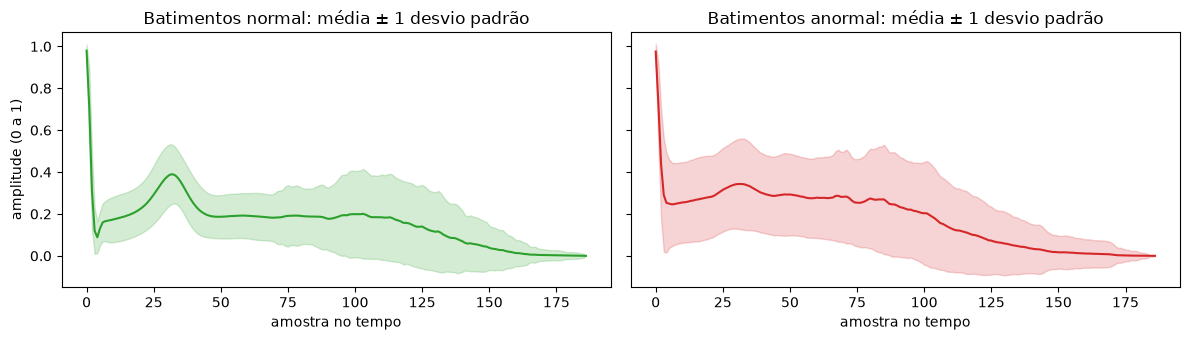

In [3]:
t = np.arange(X.shape[1])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for i, (rot, cor) in enumerate([("normal", "tab:green"), ("anormal", "tab:red")]):
    grupo = X[y == i]
    media, dp = grupo.mean(0), grupo.std(0)
    ax[i].plot(t, media, color=cor)
    ax[i].fill_between(t, media - dp, media + dp, color=cor, alpha=0.2)
    ax[i].set_title(f"Batimentos {rot}: média ± 1 desvio padrão")
    ax[i].set_xlabel("amostra no tempo")
ax[0].set_ylabel("amplitude (0 a 1)")
plt.tight_layout()
plt.savefig("figuras/01_media_por_classe.png", dpi=110)
plt.show()

## 3. Divisão treino, validação e teste

Mesma divisão da Fase 2: 70% treino, 15% validação, 15% teste, estratificado. A validação serve para escolher a melhor época da rede LIF. O teste só é usado no final, uma única vez, para os dois modelos.

In [4]:
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print("Treino:", X_tr.shape, "| Validação:", X_va.shape, "| Teste:", X_te.shape)


def metricas(y_true, y_pred):
    # recall, precisão e F1 calculados para a classe 1 (anormal)
    return {"acuracia": accuracy_score(y_true, y_pred),
            "recall_anormal": recall_score(y_true, y_pred),
            "precisao_anormal": precision_score(y_true, y_pred),
            "f1_anormal": f1_score(y_true, y_pred)}

Treino: (10186, 187) | Validação: (2183, 187) | Teste: (2183, 187)


## 4. Modelo 1: Regressão Logística

Recebe os 187 valores do batimento e calcula uma soma ponderada: `z = w·x + b`. A probabilidade de anormal é `sigmoid(z)`. Ou seja, cada instante do sinal tem um peso fixo. Não há memória nem noção de ordem: trocar a posição de dois pontos muda o resultado só porque os pesos daquela posição são diferentes.

`StandardScaler` deixa cada posição com média 0 e desvio 1 antes do modelo, o que ajuda o otimizador. Testei C (força da regularização) de 0,01 a 100 na validação e o resultado quase não mudou (de 76,8% a 78,4%), então fiquei com o padrão C = 1.

In [5]:
logistica = make_pipeline(StandardScaler(),
                          LogisticRegression(C=1.0, max_iter=5000, class_weight="balanced"))
t0 = time.perf_counter()
logistica.fit(X_tr, y_tr)
tempo_treino_lr = time.perf_counter() - t0

pred_lr = logistica.predict(X_te)
params_lr = logistica[-1].coef_.size + logistica[-1].intercept_.size
res_lr = metricas(y_te, pred_lr)
print(f"Treino: {tempo_treino_lr:.2f} s | parâmetros: {params_lr}")
print({k: round(v, 4) for k, v in res_lr.items()})

Treino: 0.39 s | parâmetros: 188
{'acuracia': 0.7833, 'recall_anormal': 0.7836, 'precisao_anormal': 0.9034, 'f1_anormal': 0.8393}


## 5. O neurônio LIF (Leaky Integrate-and-Fire)

É o modelo de neurônio usado nos chips neuromórficos estudados no capítulo 3 (o TrueNorth usa uma variação dele). A ideia, em tempo discreto:

$$v[t] = \beta \, v[t-1] + I[t] - \theta \, s[t-1] \qquad s[t] = \begin{cases}1 & \text{se } v[t] \ge \theta\\ 0 & \text{caso contrário}\end{cases}$$

- **integra** (*integrate*): soma a corrente de entrada $I[t]$ no potencial de membrana $v$;
- **vaza** (*leaky*): a cada passo o potencial perde uma parte ($\beta < 1$), então entrada antiga vai sendo esquecida;
- **dispara** (*fire*): quando $v$ passa do limiar $\theta$, solta um spike (1) e o potencial cai $\theta$ (reset por subtração).

A diferença para a regressão logística é que o LIF **tem memória**: o que aconteceu alguns passos atrás ainda está no potencial. E a saída não é um número contínuo, é um trem de pulsos.

Primeiro, um neurônio sozinho recebendo uma corrente constante, só para ver o comportamento:

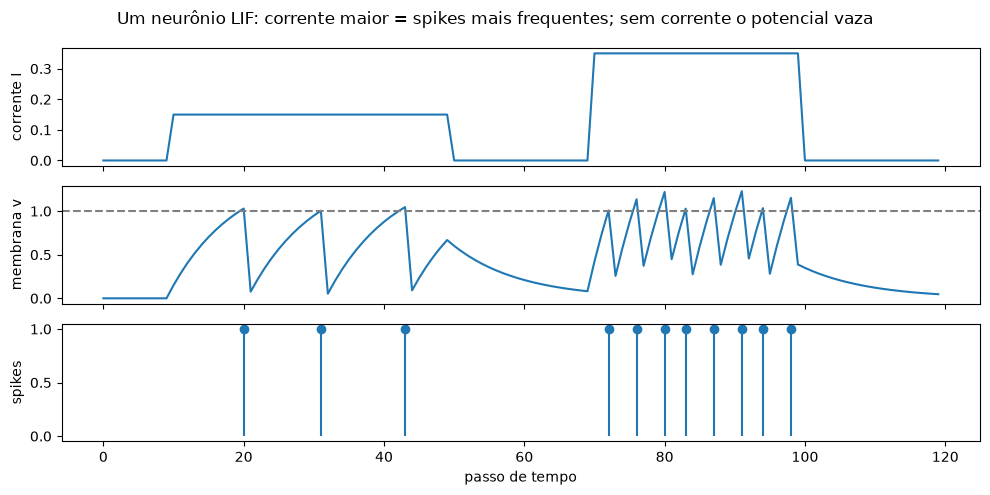

Spikes com corrente 0,15: 3 | com corrente 0,35: 8


In [6]:
def simular_lif(corrente, beta=0.9, limiar=1.0):
    v, s, hist_v, hist_s = 0.0, 0.0, [], []
    for i in corrente:
        v = beta * v + i - limiar * s
        s = 1.0 if v >= limiar else 0.0
        hist_v.append(v)
        hist_s.append(s)
    return np.array(hist_v), np.array(hist_s)

corrente = np.r_[np.zeros(10), np.full(40, 0.15), np.zeros(20), np.full(30, 0.35), np.zeros(20)]
v, s = simular_lif(corrente)
fig, ax = plt.subplots(3, 1, figsize=(10, 5), sharex=True)
ax[0].plot(corrente); ax[0].set_ylabel("corrente I")
ax[1].plot(v); ax[1].axhline(1.0, ls="--", c="gray"); ax[1].set_ylabel("membrana v")
ax[2].stem(np.where(s)[0], np.ones(int(s.sum())), basefmt=" "); ax[2].set_ylabel("spikes")
ax[2].set_xlabel("passo de tempo")
fig.suptitle("Um neurônio LIF: corrente maior = spikes mais frequentes; sem corrente o potencial vaza")
plt.tight_layout(); plt.savefig("figuras/02_neuronio_lif.png", dpi=110); plt.show()
print("Spikes com corrente 0,15:", int(s[10:50].sum()), "| com corrente 0,35:", int(s[70:100].sum()))

## 6. Transformando o ECG em spikes

Chips neuromórficos não recebem números, recebem eventos. Uso **codificação por cruzamento de nível** (*level crossing*), parecida com a de sensores baseados em eventos: defino 16 níveis de amplitude entre 0 e 1. Cada nível tem dois canais de entrada:

- **SOBE_k** dispara quando o sinal cruza o nível k para cima;
- **DESCE_k** dispara quando cruza para baixo.

São 32 canais. Quando o sinal está parado (ou no zero de preenchimento do fim do batimento), **não sai evento nenhum**. É aí que um hardware neuromórfico economiza energia: sem evento, sem conta.

In [7]:
N_NIVEIS = 16
NIVEIS = np.linspace(0.02, 0.98, N_NIVEIS).astype(np.float32)


def codificar_spikes(Xs):
    # Compara cada ponto com o anterior em todos os níveis de uma vez (vetorizado)
    ant, atu = Xs[:, :-1, None], Xs[:, 1:, None]
    sobe = (ant < NIVEIS) & (atu >= NIVEIS)
    desce = (ant >= NIVEIS) & (atu < NIVEIS)
    eventos = np.concatenate([sobe, desce], axis=2)
    inicio = np.zeros((len(Xs), 1, 2 * N_NIVEIS), dtype=bool)   # t = 0 não tem anterior
    return np.concatenate([inicio, eventos], axis=1)            # formato: batimentos x tempo x canais

S_tr, S_va, S_te = codificar_spikes(X_tr), codificar_spikes(X_va), codificar_spikes(X_te)
T_PASSOS, N_CANAIS = S_tr.shape[1], S_tr.shape[2]
spikes_entrada = S_te.sum(axis=(1, 2))
ocupacao = spikes_entrada.mean() / (T_PASSOS * N_CANAIS)
print(f"Formato: {S_tr.shape} | memória (bool): {S_tr.nbytes / 1e6:.0f} MB")
print(f"Spikes de entrada por batimento: média {spikes_entrada.mean():.1f} "
      f"(de {T_PASSOS * N_CANAIS} posições possíveis = {ocupacao:.1%} ocupadas)")

Formato: (10186, 187, 32) | memória (bool): 61 MB
Spikes de entrada por batimento: média 76.0 (de 5984 posições possíveis = 1.3% ocupadas)


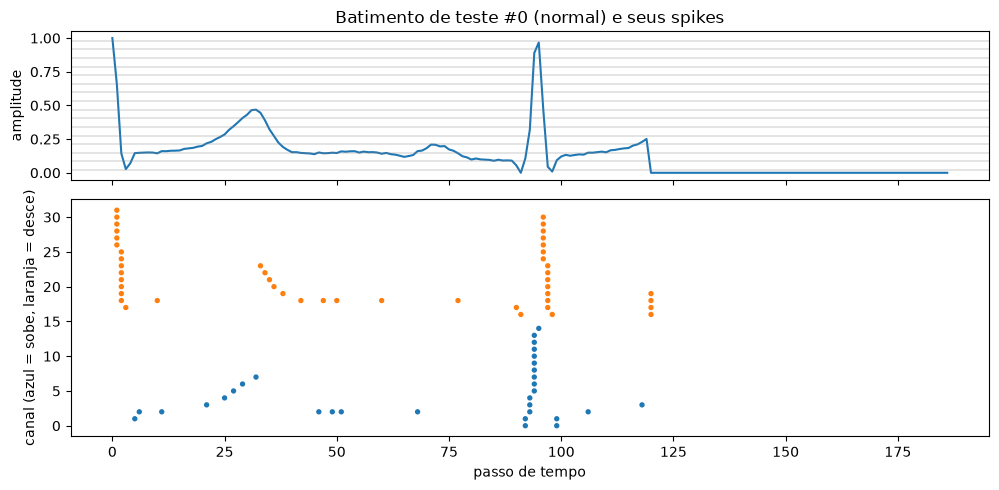

In [8]:
i = 0
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True, gridspec_kw={"height_ratios": [1, 1.6]})
ax[0].plot(X_te[i]); ax[0].set_ylabel("amplitude")
ax[0].set_title(f"Batimento de teste #{i} ({'anormal' if y_te[i] else 'normal'}) e seus spikes")
for nivel in NIVEIS:
    ax[0].axhline(nivel, lw=0.3, c="gray")
tt, cc = np.where(S_te[i])
ax[1].scatter(tt, cc, s=8, c=np.where(cc < N_NIVEIS, "tab:blue", "tab:orange"))
ax[1].set_ylabel("canal (azul = sobe, laranja = desce)"); ax[1].set_xlabel("passo de tempo")
plt.tight_layout(); plt.savefig("figuras/03_raster_spikes.png", dpi=110); plt.show()

## 7. Modelo 2: rede de neurônios LIF

**Arquitetura:** 32 canais de spikes → 64 neurônios LIF → leitura linear → 2 classes.

- Cada neurônio oculto tem seu próprio $\beta$, sorteado entre 0,85 e 0,98. Neurônios com $\beta$ alto lembram por mais tempo, com $\beta$ baixo reagem a mudanças rápidas. Essa variedade ajuda a captar padrões de durações diferentes (onda P, complexo QRS, onda T).
- **Leitura por janelas:** o batimento é dividido em 8 janelas de tempo e conto quantos spikes cada neurônio deu em cada janela. A camada de saída é linear sobre essas contagens. Sem as janelas, um spike no começo e um no fim do batimento valeriam igual, e no ECG a posição importa (alterações do segmento ST, por exemplo).

**Como treinar se o spike é um degrau?** A derivada de um degrau é zero em quase todo lugar, então o gradiente não passa. A solução usada na área (gradiente substituto, *surrogate gradient*) é: no passo para frente usa o degrau de verdade; no passo para trás finge que a derivada é uma curva suave em volta do limiar, $\frac{1}{(1 + k|v-\theta|)^2}$. O erro é propagado de volta no tempo (BPTT, *backpropagation through time*), passo a passo, de $t = 186$ até $t = 0$. Isso está escrito à mão no método `_retropropagar`.

O otimizador é o Adam, também escrito à mão (são 6 linhas).

In [9]:
class RedeLIF:
    # Rede de 1 camada oculta de neurônios LIF com leitura por janelas, só NumPy.

    def __init__(self, n_entrada, n_ocultos=64, n_janelas=8, n_passos=187, limiar=1.0,
                 inclinacao=5.0, semente=SEED):
        r = np.random.default_rng(semente)
        self.H, self.J, self.T = n_ocultos, n_janelas, n_passos
        self.limiar, self.k = limiar, inclinacao
        self.beta = r.uniform(0.85, 0.98, n_ocultos).astype(np.float32)   # fixo, não treinado
        self.W1 = r.normal(0, 1.0, (n_entrada, n_ocultos)).astype(np.float32)
        self.b1 = np.zeros(n_ocultos, np.float32)
        self.W2 = r.normal(0, 0.1, (n_ocultos * n_janelas, 2)).astype(np.float32)
        self.b2 = np.zeros(2, np.float32)
        self.janela_de = np.minimum(np.arange(n_passos) * n_janelas // n_passos, n_janelas - 1)
        self.passos_por_janela = n_passos / n_janelas

    @property
    def params(self):
        return [self.W1, self.b1, self.W2, self.b2]

    def n_parametros(self):
        return sum(p.size for p in self.params)

    def _avancar(self, S, guardar=False):
        # Simula a rede no tempo. Devolve logits, contagens por janela e (se treino) as membranas.
        B = S.shape[0]
        v = np.zeros((B, self.H), np.float32)
        s = np.zeros((B, self.H), np.float32)
        contagem = np.zeros((B, self.J, self.H), np.float32)
        membranas = [] if guardar else None
        for t in range(self.T):
            corrente = S[:, t].astype(np.float32) @ self.W1 + self.b1
            v = self.beta * v + corrente - self.limiar * s       # integra, vaza e reseta
            s = (v >= self.limiar).astype(np.float32)           # dispara
            contagem[:, self.janela_de[t]] += s
            if guardar:
                membranas.append(v)
        f = contagem.reshape(B, -1) / self.passos_por_janela
        return f @ self.W2 + self.b2, f, membranas, contagem

    def _retropropagar(self, S, y, logits, f, membranas, peso_classe):
        B = S.shape[0]
        z = logits - logits.max(1, keepdims=True)
        p = np.exp(z); p /= p.sum(1, keepdims=True)                 # softmax
        w = peso_classe[y]
        perda = -(w * np.log(p[np.arange(B), y] + 1e-9)).sum() / w.sum()
        g = p.copy(); g[np.arange(B), y] -= 1; g *= (w / w.sum())[:, None]   # d(perda)/d(logits)
        gW2, gb2 = f.T @ g, g.sum(0)
        g_spk = (g @ self.W2.T).reshape(B, self.J, self.H) / self.passos_por_janela
        gW1, gb1 = np.zeros_like(self.W1), np.zeros_like(self.b1)
        g_v_futuro = np.zeros((B, self.H), np.float32)
        for t in range(self.T - 1, -1, -1):                         # de trás para frente no tempo
            substituto = 1.0 / (1.0 + self.k * np.abs(membranas[t] - self.limiar)) ** 2
            g_v = g_spk[:, self.janela_de[t]] * substituto + self.beta * g_v_futuro
            gW1 += S[:, t].astype(np.float32).T @ g_v
            gb1 += g_v.sum(0)
            g_v_futuro = g_v
        return perda, [gW1, gb1, gW2, gb2]

    def prever(self, S, lote=512):
        return np.concatenate([self._avancar(S[i:i + lote])[0].argmax(1) for i in range(0, len(S), lote)])

    def contar_spikes(self, S, lote=512):
        return np.concatenate([self._avancar(S[i:i + lote])[3].sum(axis=(1, 2)) for i in range(0, len(S), lote)])

    def treinar(self, S, y, S_val, y_val, epocas=30, lote=128, taxa=5e-3, reduzir_em=20):
        peso_classe = len(y) / (2 * np.bincount(y))                 # mesmo papel do class_weight
        m = [np.zeros_like(p) for p in self.params]
        v2 = [np.zeros_like(p) for p in self.params]
        passo, historico = 0, []
        melhor_f1, melhores = -1, None
        r = np.random.default_rng(SEED)
        for ep in range(1, epocas + 1):
            if ep == reduzir_em:
                taxa /= 2                                           # passos menores no fim do treino
            ordem, perdas = r.permutation(len(S)), []
            for i in range(0, len(S), lote):
                b = ordem[i:i + lote]
                logits, f, membranas, _ = self._avancar(S[b], guardar=True)
                perda, grads = self._retropropagar(S[b], y[b], logits, f, membranas, peso_classe)
                perdas.append(perda)
                passo += 1
                for j, (p, gp) in enumerate(zip(self.params, grads)):   # Adam
                    m[j] = 0.9 * m[j] + 0.1 * gp
                    v2[j] = 0.999 * v2[j] + 0.001 * gp * gp
                    p -= taxa * (m[j] / (1 - 0.9 ** passo)) / (np.sqrt(v2[j] / (1 - 0.999 ** passo)) + 1e-8)
            f1_val = f1_score(y_val, self.prever(S_val))
            historico.append({"epoca": ep, "perda": float(np.mean(perdas)), "f1_val": f1_val})
            if f1_val > melhor_f1:                                  # guarda a melhor época na validação
                melhor_f1, melhores = f1_val, [p.copy() for p in self.params]
                melhor_ep = ep
            print(f"época {ep:2d} | perda {np.mean(perdas):.4f} | F1 validação {f1_val:.4f}")
        for p, mp in zip(self.params, melhores):                    # volta para os melhores pesos
            p[...] = mp
        print(f"Melhor época: {melhor_ep} (F1 validação {melhor_f1:.4f})")
        return historico, melhor_ep

In [10]:
rede = RedeLIF(n_entrada=N_CANAIS, n_ocultos=64, n_janelas=8, n_passos=T_PASSOS)
t0 = time.perf_counter()
historico, melhor_ep = rede.treinar(S_tr, y_tr, S_va, y_va, epocas=30)
tempo_treino_lif = time.perf_counter() - t0
print(f"Tempo de treino: {tempo_treino_lif:.0f} s | parâmetros treináveis: {rede.n_parametros()}")

época  1 | perda 0.5161 | F1 validação 0.8634


época  2 | perda 0.4001 | F1 validação 0.8519


época  3 | perda 0.3540 | F1 validação 0.9169


época  4 | perda 0.3336 | F1 validação 0.8977


época  5 | perda 0.3124 | F1 validação 0.9282


época  6 | perda 0.2989 | F1 validação 0.9049


... (20 outputs left out)

época 27 | perda 0.2023 | F1 validação 0.9331


época 28 | perda 0.2009 | F1 validação 0.9381


época 29 | perda 0.1985 | F1 validação 0.9392


época 30 | perda 0.1965 | F1 validação 0.9360
Melhor época: 20 (F1 validação 0.9462)
Tempo de treino: 47 s | parâmetros treináveis: 3138


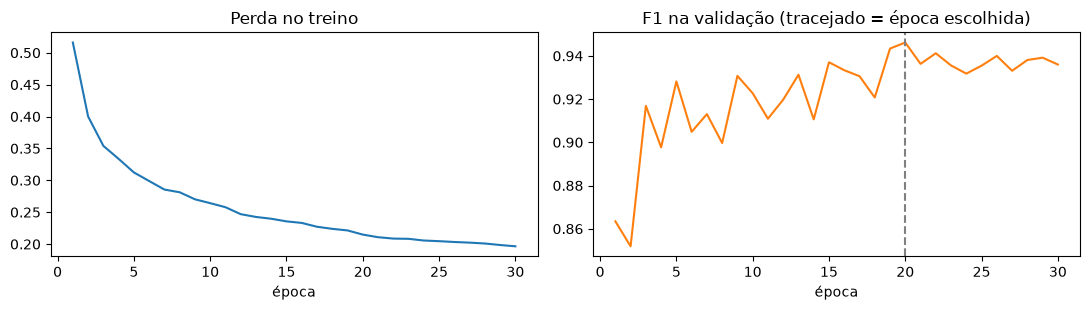

In [11]:
h = pd.DataFrame(historico)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].plot(h.epoca, h.perda); ax[0].set_title("Perda no treino"); ax[0].set_xlabel("época")
ax[1].plot(h.epoca, h.f1_val, c="tab:orange"); ax[1].axvline(melhor_ep, ls="--", c="gray")
ax[1].set_title("F1 na validação (tracejado = época escolhida)"); ax[1].set_xlabel("época")
plt.tight_layout(); plt.savefig("figuras/04_treino_lif.png", dpi=110); plt.show()

## 8. Avaliação no teste (as duas abordagens, mesma base de teste)

In [12]:
pred_lif = rede.prever(S_te)
res_lif = metricas(y_te, pred_lif)

# Tempo de inferência por 1000 batimentos: (segundos / n) x 1e6 = ms por 1000.
# A regressão inclui o StandardScaler e a LIF inclui a codificação em spikes.
t0 = time.perf_counter(); logistica.predict(X_te); ms_lr = (time.perf_counter() - t0) / len(X_te) * 1e6
t0 = time.perf_counter(); rede.prever(codificar_spikes(X_te)); ms_lif = (time.perf_counter() - t0) / len(X_te) * 1e6

spk_ocultos = rede.contar_spikes(S_te)
tabela = pd.DataFrame({
    "Regressão Logística": {**res_lr, "tempo_treino_s": tempo_treino_lr,
                            "ms_por_1000_batimentos": ms_lr, "parametros": params_lr},
    "Rede LIF (NumPy)": {**res_lif, "tempo_treino_s": tempo_treino_lif,
                         "ms_por_1000_batimentos": ms_lif, "parametros": rede.n_parametros()},
})
display(tabela.style.format("{:.4f}", subset=pd.IndexSlice[["acuracia", "recall_anormal", "precisao_anormal", "f1_anormal"], :])
        .format("{:.1f}", subset=pd.IndexSlice[["tempo_treino_s", "ms_por_1000_batimentos"], :])
        .format("{:.0f}", subset=pd.IndexSlice[["parametros"], :]))

,Regressão Logística,Rede LIF (NumPy)
acuracia,0.7833,0.9098
recall_anormal,0.7836,0.9283
precisao_anormal,0.9034,0.9457
f1_anormal,0.8393,0.9369
tempo_treino_s,0.4,47.3
ms_por_1000_batimentos,0.9,103.7
parametros,188,3138


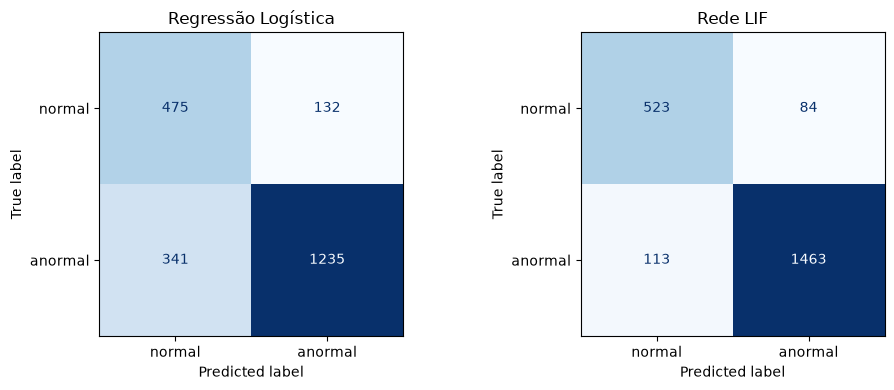

==================== Regressão Logística
              precision    recall  f1-score   support

      normal     0.5821    0.7825    0.6676       607
     anormal     0.9034    0.7836    0.8393      1576

    accuracy                         0.7833      2183
   macro avg     0.7428    0.7831    0.7534      2183
weighted avg     0.8141    0.7833    0.7915      2183

==================== Rede LIF
              precision    recall  f1-score   support

      normal     0.8223    0.8616    0.8415       607
     anormal     0.9457    0.9283    0.9369      1576

    accuracy                         0.9098      2183
   macro avg     0.8840    0.8950    0.8892      2183
weighted avg     0.9114    0.9098    0.9104      2183



In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, pred, titulo in [(ax[0], pred_lr, "Regressão Logística"), (ax[1], pred_lif, "Rede LIF")]:
    ConfusionMatrixDisplay.from_predictions(y_te, pred, display_labels=["normal", "anormal"],
                                            ax=a, colorbar=False, cmap="Blues")
    a.set_title(titulo)
plt.tight_layout(); plt.savefig("figuras/05_matrizes_confusao.png", dpi=110); plt.show()

for nome, pred in [("Regressão Logística", pred_lr), ("Rede LIF", pred_lif)]:
    print("=" * 20, nome)
    print(classification_report(y_te, pred, target_names=["normal", "anormal"], digits=4))

## 9. Controle: de onde vem o ganho?

A rede LIF recebeu o sinal já transformado em spikes. Será que o ganho é da codificação e não do neurônio? Para separar as duas coisas, treino a **mesma regressão logística** sobre a contagem de spikes de entrada em cada uma das 8 janelas (32 canais x 8 janelas = 256 atributos). Se ela empatar com a LIF, a dinâmica do neurônio não estaria ajudando.

In [14]:
def contagem_por_janela(S, n_janelas=8):
    jan = np.minimum(np.arange(S.shape[1]) * n_janelas // S.shape[1], n_janelas - 1)
    return np.stack([S[:, jan == j].sum(1) for j in range(n_janelas)], 1).reshape(len(S), -1).astype(np.float32)

lr_spikes = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, class_weight="balanced"))
lr_spikes.fit(contagem_por_janela(S_tr), y_tr)
res_ctrl = metricas(y_te, lr_spikes.predict(contagem_por_janela(S_te)))
comparacao = pd.DataFrame({"LR sobre o sinal": res_lr, "LR sobre os spikes": res_ctrl, "Rede LIF": res_lif}).T
display(comparacao.style.format("{:.4f}"))

,acuracia,recall_anormal,precisao_anormal,f1_anormal
LR sobre o sinal,0.7833,0.7836,0.9034,0.8393
LR sobre os spikes,0.8140,0.7951,0.9379,0.8606
Rede LIF,0.9098,0.9283,0.9457,0.9369


## 10. Custo computacional e atividade de spikes

Na CPU comum a simulação faz a conta inteira em todos os 187 passos, mesmo quando não há evento. Num chip neuromórfico só custa quando chega spike. Então calculo as duas contagens: operações densas (o que a CPU fez) e eventos sinápticos (o que um hardware orientado a eventos faria).

In [15]:
ops_lr = 187 * 2 + 187 + 1                                   # padronização (sub e div) + soma ponderada
ops_lif_denso = T_PASSOS * (N_CANAIS * rede.H + 3 * rede.H) + rede.W2.size
eventos_sinapticos = spikes_entrada.mean() * rede.H          # cada spike de entrada soma 1 linha de W1
custo = pd.DataFrame({
    "Regressão Logística": {"operacoes_por_batimento": ops_lr, "spikes_entrada": np.nan, "spikes_ocultos": np.nan},
    "LIF em CPU (denso)": {"operacoes_por_batimento": ops_lif_denso, "spikes_entrada": spikes_entrada.mean(),
                           "spikes_ocultos": spk_ocultos.mean()},
    "LIF orientado a eventos": {"operacoes_por_batimento": eventos_sinapticos + spk_ocultos.mean() * 2 + T_PASSOS * rede.H,
                                "spikes_entrada": spikes_entrada.mean(), "spikes_ocultos": spk_ocultos.mean()},
}).T
display(custo.style.format("{:,.0f}"))
atividade = spk_ocultos.mean() / (T_PASSOS * rede.H)
print(f"Atividade da camada oculta: {atividade:.1%} dos neurônios disparam a cada passo, em média")

,operacoes_por_batimento,spikes_entrada,spikes_ocultos
Regressão Logística,562,nan,nan
LIF em CPU (denso),"419,904",76,"1,334"
LIF orientado a eventos,"19,501",76,"1,334"


Atividade da camada oculta: 11.1% dos neurônios disparam a cada passo, em média


In [16]:
resultados = {
    "regressao_logistica": {**res_lr, "tempo_treino_s": tempo_treino_lr, "ms_por_1000": ms_lr, "parametros": int(params_lr)},
    "rede_lif": {**res_lif, "tempo_treino_s": tempo_treino_lif, "ms_por_1000": ms_lif,
                 "parametros": int(rede.n_parametros()), "melhor_epoca": int(melhor_ep),
                 "spikes_entrada_medio": float(spikes_entrada.mean()), "spikes_ocultos_medio": float(spk_ocultos.mean())},
    "controle_lr_spikes": res_ctrl,
    "custo": {k: {kk: (None if pd.isna(vv) else float(vv)) for kk, vv in v.items()} for k, v in custo.T.to_dict().items()},
}
with open("resultados/metricas.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=2, default=float)
print(json.dumps(resultados, ensure_ascii=False, indent=2, default=float))

{
  "regressao_logistica": {
    "acuracia": 0.7833256985799358,
    "recall_anormal": 0.7836294416243654,
    "precisao_anormal": 0.9034381858083395,
    "f1_anormal": 0.8392796466190962,
    "tempo_treino_s": 0.3913606000132859,
    "ms_por_1000": 0.9049931404565215,
    "parametros": 188
  },
  "rede_lif": {
    "acuracia": 0.9097572148419606,
    "recall_anormal": 0.9282994923857868,
    "precisao_anormal": 0.9457013574660633,
    "f1_anormal": 0.9369196285622798,
    "tempo_treino_s": 47.31932630005758,
    "ms_por_1000": 103.66486485721565,
    "parametros": 3138,
    "melhor_epoca": 20,
    "spikes_entrada_medio": 76.0201557489693,
    "spikes_ocultos_medio": 1333.87353515625
  },
  "controle_lr_spikes": {
    "acuracia": 0.8140174072377462,
    "recall_anormal": 0.7950507614213198,
    "precisao_anormal": 0.937874251497006,
    "f1_anormal": 0.8605769230769231
  },
  "custo": {
    "Regressão Logística": {
      "operacoes_por_batimento": 562.0,
      "spikes_entrada": null,
  

## 11. Discussão crítica

Os números abaixo são os desta execução (base de teste com 2.183 batimentos, 1.576 anormais). Rodei o notebook várias vezes: as métricas saíram idênticas em todas (semente fixa); os tempos variam com o que mais está rodando no computador, então mostro a faixa observada. Os valores exatos desta execução estão na tabela da seção 8.

| | Regressão Logística | Rede LIF |
|---|---|---|
| Acurácia | 78,3% | 91,0% |
| Recall anormal | 78,4% (1.235 de 1.576) | 92,8% (1.463 de 1.576) |
| F1 anormal | 0,839 | 0,937 |
| Parâmetros treináveis | 188 | 3.138 |
| Tempo de treino | 0,4 a 0,7 s | 47 a 65 s |
| Inferência (1000 batimentos, CPU) | 0,8 a 1,7 ms | 101 a 155 ms |

### Desempenho: a LIF erra bem menos o caso perigoso

A regressão logística deixou passar 341 batimentos anormais; a rede LIF, 113. Para triagem é a diferença que mais importa. O motivo está no jeito de cada modelo olhar o sinal. A logística dá um peso fixo para cada uma das 187 posições. Se o mesmo pico aparece na posição 60 num batimento e na 65 em outro (batimentos têm duração e alinhamento diferentes), para ela são coisas distintas, e ela só consegue traçar uma fronteira linear. O neurônio LIF integra a entrada ao longo do tempo e esquece aos poucos: ele responde ao **formato** e ao **ritmo** da subida e da descida, não à posição exata. Os valores de β diferentes entre neurônios funcionam como janelas de memória de tamanhos diferentes.

### O controle mostra que não é só a codificação

A mesma logística sobre as contagens de spikes de entrada chegou a 81,4%. Ou seja: transformar o sinal em eventos já ajuda cerca de 3 pontos, mas a maior parte do ganho (mais uns 10 pontos) vem da dinâmica dos neurônios LIF. Sem esse controle eu não conseguiria separar as duas coisas.

### Custo: na CPU, a rede neuromórfica é muito mais cara

A logística tem 188 parâmetros, treina em menos de 1 s e faz cerca de 562 operações por batimento. Ela caberia folgada no próprio ESP32 da Parte 1. A LIF simulada em CPU faz a conta completa nos 187 passos de tempo, cerca de 420 mil operações por batimento, e ficou cerca de 100 vezes mais lenta na inferência (duas ordens de grandeza).

Isso confirma o que o capítulo 3 mostra com o experimento de Freitas et al.: SNN rodando em arquitetura Von Neumann não economiza energia, pode até gastar mais. A vantagem aparece em hardware orientado a eventos, como o Loihi e o TrueNorth, onde só se gasta quando chega um spike. Os dados ajudam essa tese: só 1,3% das posições de entrada têm evento e só 11,1% dos neurônios ocultos disparam por passo. Contando apenas os eventos, a estimativa cai para cerca de 19,5 mil operações por batimento. Ainda é mais que a logística, mas a conta é de outra natureza (somas disparadas por evento, sem multiplicação densa). Essa estimativa é um modelo simples, não uma medição de energia em chip.

### Vantagens e limitações de cada um

**Regressão logística.** Vantagens: rápida, minúscula, estável, fácil de explicar (cada peso diz quanto aquela posição do sinal puxa para anormal). Limitações: fronteira linear, sem noção de tempo; com 78% de acurácia ela erraria mais de 1 em cada 5 batimentos anormais.

**Rede LIF.** Vantagens: capta padrões temporais, trabalha com eventos esparsos (natural para sensores vestíveis e chips neuromórficos) e teve resultado bem melhor. Limitações: treino mais difícil (o spike não tem derivada, foi preciso gradiente substituto e BPTT escritos à mão), mais hiperparâmetros (níveis de codificação, β, limiar, janelas), oscilação da validação entre épocas (por isso guardei a melhor), mais difícil de interpretar e, sem hardware próprio, mais lenta.

Escolhi LIF e não FitzHugh-Nagumo porque o LIF tem uma única variável de estado e conta barata por passo. O FHN tem duas variáveis e um termo cúbico: reproduz melhor a forma do potencial de ação biológico, mas isso não é necessário para classificar e deixaria a simulação mais cara.

### Cuidados com os resultados

- **Mesmo paciente no treino e no teste.** O PTB vem em batimentos soltos, sem identificador do paciente. Batimentos da mesma pessoa provavelmente caíram dos dois lados, o que deixa os dois modelos otimistas. O certo seria separar por paciente.
- **Uma única divisão e uma única semente.** Sem validação cruzada não tenho intervalo de confiança. A diferença de 12 pontos é grande o bastante para não ser sorte, mas os valores exatos mudariam com outra divisão.
- **Ajuste limitado.** Testei poucas configurações da LIF na validação (16 ou 24 níveis, 64 ou 128 neurônios, 4 ou 8 janelas) e fiquei com a menor que funcionou bem.
- **Não é o melhor modelo possível.** A MLP sobre imagens da Fase 2 chegou a 97,5% de acurácia nesta mesma base. A comparação aqui é entre um classificador linear e uma SNN simples, não uma disputa pelo estado da arte.

### O que isso significa para o CardioIA

Para o wearable da Parte 1, a regressão logística é a escolha realista hoje: roda no ESP32, responde na hora e dá para explicar o alerta. A rede LIF mostra o caminho para quando houver um chip neuromórfico no dispositivo: mais precisão com custo baixo por evento, o que importa em equipamento a bateria. Uma arquitetura híbrida faria sentido: triagem simples na borda e o modelo mais forte na névoa ou na nuvem, revisando os casos duvidosos.